## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → I choose this file.
2. The dataset: `Superstore Dataset (vivek468).zip` is in my `C:\Users\sivan\Datasets` folder.
3. When the upload cell asks for a file, I choose `Superstore Dataset (vivek468).zip`.
4. I run the cells from top to bottom (Shift+Enter runs one cell). After a restart I run them again from the top.

**About the data file:** the exercise gives the data as an Excel file, `US Superstore data.xls`. The same data (same 9,994 rows and 21 columns, same totals) is also on Kaggle as a CSV file ([US Superstore – vivek468](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)). I already had that CSV zipped in my Datasets folder, so I use the CSV. I checked that both files have the same rows, columns and totals.

For the map I use `plotly`, which is already installed in Colab.

# Daily Challenge: Interactive Data Visualization with Matplotlib and Seaborn

## Key insights
- Sales grew from \$470K in 2015 to \$733K in 2017. Profit grew every year, from \$50K (2014) to \$93K (2017). September, November and December are the strongest months.
- The data is US only, so I show the map **by state**: California and New York lead.
- The top product is the Canon imageCLASS 2200 Advanced Copier (\$61,600), more than double the 2nd product.
- Discounts hurt profit: from a 30% discount on, the average profit is negative (correlation −0.22).

**My steps:**
1. Import the libraries
2. Load, explore and clean the data
3. Interactive line chart of sales over the years (Matplotlib)
4. Interactive map of sales (by state)
5. Top 10 products by sales (Seaborn)
6. Profit vs discount (Seaborn)
7. Comparing Matplotlib and Seaborn

## Step 1. Import the libraries
> **New here: `ipywidgets`.** `interact(my_function, year=[...])` shows a dropdown above the chart; when I pick a value it runs my function again with it. It only reacts in a live notebook (in Colab), not in the saved file.
>
> **New here: `plotly.express`.** Matplotlib can't make an interactive map easily, so for the map I use `px.choropleth`, which colors each state and shows its numbers when I hover over it.

In [1]:
import pandas as pd
# pandas: for tables (DataFrames)
import numpy as np
# numpy: for number calculations
import matplotlib.pyplot as plt
# matplotlib: for drawing charts
import seaborn as sns
# seaborn: nicer charts built on matplotlib
sns.set_theme(style='whitegrid')
# I give all charts a white background with grid lines
from ipywidgets import interact
# interact: makes a dropdown that redraws my chart
import plotly.express as px
# plotly express: for the interactive map

## Step 2. Load, explore and clean the data
**What I want to find:** the size of the data, missing values, duplicates, and the dates as real dates.

In [ ]:
from google.colab import files
# I import the Colab tool for uploading files from my computer
uploaded = files.upload()
# I choose "Superstore Dataset (vivek468).zip" (I save it in a variable so its contents are not printed)
!unzip "Superstore Dataset (vivek468).zip"
# I unzip it: I get the file "superstore_dataset.csv"

In [3]:
df = pd.read_csv('superstore_dataset.csv', encoding='latin1')
# I read the CSV into a table; encoding='latin1' because the file has characters that are not UTF-8 (without it I get an error)
# df = pd.read_excel('US Superstore data.xls')
# (how I would read the Excel version instead; for an old .xls file pandas needs the xlrd library)
print(df.shape)
# I print (rows, columns)
df.head()
# I show the first 5 rows

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.info()
# I see each column's name, data type and how many values are not empty

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
print(df.isnull().sum().sum())
# isnull() marks empty cells, the two sum() count them in the whole table
print(df.duplicated().sum())
# duplicated() marks rows that are exact copies of an earlier row; sum() counts them
df = df.drop_duplicates()
# I remove copied rows (there are none, but it is a standard cleaning step)
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
# I turn the date text (month/day/year) into real dates
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
# the same for the ship date
df['Year'] = df['Order Date'].dt.year
# .dt.year takes the year out of each date: a new column 'Year'
df['Month'] = df['Order Date'].dt.month
# .dt.month takes the month number (1-12): a new column 'Month'
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()
# describe() gives count, mean, min, max etc. of the number columns

0
0


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


**What the result shows:** 9,994 rows and 21 columns, no missing values and no duplicates. The dates were text, so I converted them and added Year and Month columns. The orders are from 2014 to 2017.

## Step 3. Interactive line chart: sales trends over the years (Matplotlib)
**What I want to find:** how sales change from month to month in each year, with a dropdown to choose the year, and the total per year.

In [6]:
def plot_year(year):
    # my function: draws the monthly sales of one year
    data = df[df['Year'] == year].groupby('Month')['Sales'].sum()
    # I keep only that year's rows and add up the sales of each month
    plt.figure(figsize=(9, 4))
    # chart size
    plt.plot(data.index, data.values, marker='o')
    # a line through the 12 months; marker='o' puts a dot on each month
    plt.title(f'Monthly Sales in {year}')
    # the title shows the chosen year
    plt.xlabel('Month')
    # x-axis label
    plt.ylabel('Sales (USD)')
    # y-axis label
    plt.show()
    # I display the chart

interact(plot_year, year=[2014, 2015, 2016, 2017])
# a dropdown with the 4 years; when I pick one, plot_year runs again

interactive(children=(Dropdown(description='year', options=(2014, 2015, 2016, 2017), value=2014), Output()), _…

<function __main__.plot_year(year)>

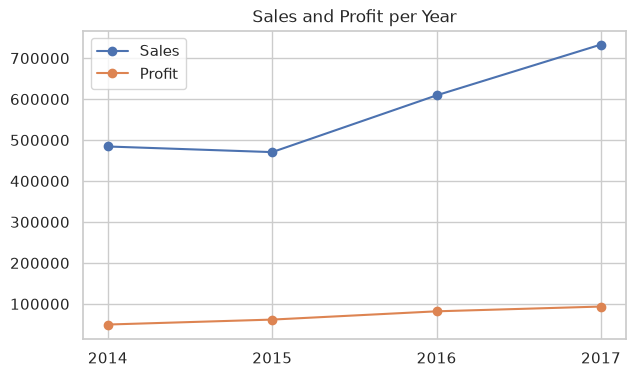

,Sales,Profit
Year,,
2014,484247.0,49544.0
2015,470533.0,61619.0
2016,609206.0,81795.0
2017,733215.0,93439.0


In [7]:
yearly = df.groupby('Year')[['Sales', 'Profit']].sum()
# total sales and profit of each year
plt.figure(figsize=(7, 4))
# chart size
plt.plot(yearly.index, yearly['Sales'], marker='o', label='Sales')
# line of yearly sales; label= is the name in the legend
plt.plot(yearly.index, yearly['Profit'], marker='o', label='Profit')
# line of yearly profit
plt.xticks(yearly.index)
# I show only the 4 years on the x-axis (no 2014.5)
plt.title('Sales and Profit per Year')
# chart title
plt.legend()
# legend: which line is which
plt.show()
# I display the chart
yearly.round(0)
# the numbers behind the chart

**What the result shows:** sales dipped a little in 2015 (\$470K vs \$484K), then grew strongly to \$733K in 2017. Profit grew every year. In every year September, November and December are the peak months.

## Step 4. Interactive map: sales distribution by country
**What I want to find:** where the sales come from. The exercise says "by country", so first I check the countries.

In [8]:
df['Country'].unique()
# unique() lists the different values: only one country

<StringArray>
['United States']
Length: 1, dtype: str

In [9]:
codes = {'Alabama': 'AL', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'District of Columbia': 'DC', 'Florida': 'FL', 'Georgia': 'GA', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD', 'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS', 'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH', 'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY'}
# a dictionary: state name -> 2-letter code (the map needs the codes)
state = df.groupby('State')['Sales'].sum().reset_index()
# total sales of each state; reset_index() makes State a normal column again
state['Code'] = state['State'].map(codes)
# map() looks up each state name in my dictionary and gives its code
fig = px.choropleth(state, locations='Code', locationmode='USA-states', color='Sales', scope='usa', hover_name='State')
# locations = the state codes, color = what colors each state, scope='usa' shows only the US, hover_name = text on hover
fig.show()
# I display the interactive map

In [10]:
state.sort_values('Sales', ascending=False).head(5)
# the top 5 states, to check what the map shows

,State,Sales,Code
3,California,457687.6315,CA
30,New York,310876.2710,NY
41,Texas,170188.0458,TX
45,Washington,138641.2700,WA
36,Pennsylvania,116511.9140,PA


**What the result shows:** the data has only one country, United States, so a country map would be one color. Instead I show sales by state. Most sales are on the two coasts: California (\$458K) and New York (\$311K), then Texas, Washington and Pennsylvania. Many central states sell very little.

## Step 5. Top 10 products by sales (Seaborn)
**What I want to find:** which products bring the most money.

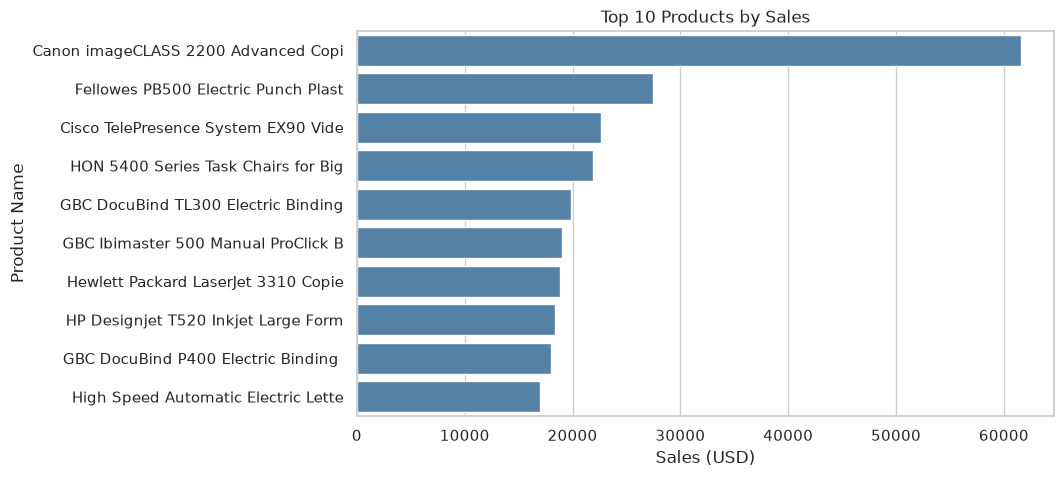

In [11]:
top10 = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)
# total sales of each product, biggest first, top 10
plt.figure(figsize=(9, 5))
# chart size
sns.barplot(x=top10.values, y=top10.index.str[:35], color='steelblue')
# horizontal bars; .str[:35] cuts the long product names to 35 characters
plt.title('Top 10 Products by Sales')
# chart title
plt.xlabel('Sales (USD)')
# x-axis label
plt.show()
# I display the chart

**What the result shows:** the Canon imageCLASS 2200 Advanced Copier is far ahead (\$61,600). Most of the top 10 are expensive office machines: binding machines, copiers, printers and a video-conference unit.

## Step 6. Profit vs Discount (Seaborn)
**What I want to find:** whether bigger discounts mean less profit.

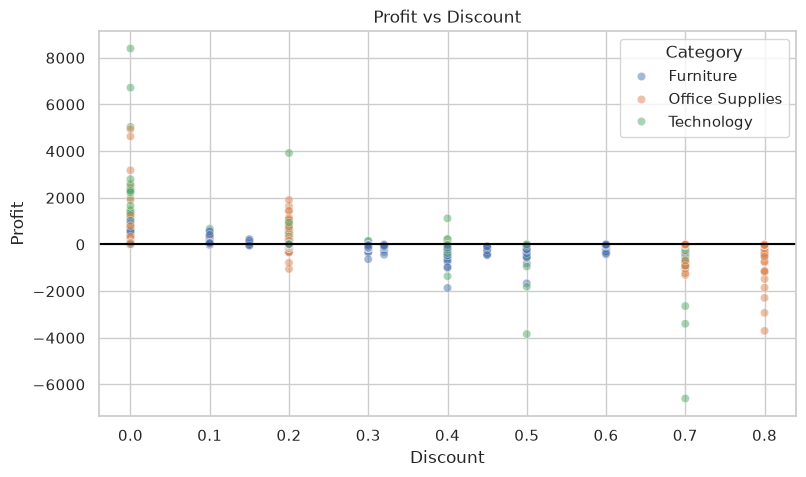

In [12]:
plt.figure(figsize=(9, 5))
# chart size
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.5)
# one dot per order line; hue colors the dots by Category; alpha=0.5 makes them half see-through
plt.axhline(0, color='black')
# a line at zero profit
plt.title('Profit vs Discount')
# chart title
plt.show()
# I display the chart

In [13]:
print(df['Discount'].corr(df['Profit']))
# corr() = correlation from -1 to 1; negative means one goes up when the other goes down
df.groupby('Discount')['Profit'].mean().round(1)
# the average profit at each discount level

-0.2194874563717678


Discount
0.00     66.9
0.10     96.1
0.15     27.3
0.20     24.7
0.30    -45.7
0.32    -88.6
0.40   -111.9
0.45   -226.6
0.50   -310.7
0.60    -43.1
0.70    -95.9
0.80   -101.8
Name: Profit, dtype: float64

**What the result shows:** the correlation is −0.22: more discount, less profit. With a 0–20% discount the average profit is positive; from 30% on it is negative (−\$311 at 50%). The big losses are at high discounts.

## Step 7. Comparing Matplotlib and Seaborn
**What each chart told me:**
- The Matplotlib line chart showed me *when* sales happen (growth, and peaks at the end of the year); the map showed me *where* (the coasts).
- The Seaborn charts showed me *what* sells (expensive office machines) and *why* profit drops (high discounts).

**Ease of use and effectiveness:**
| | Matplotlib | Seaborn |
|---|---|---|
| Ease of use | More lines; I set every detail myself | Short: one line works directly on my DataFrame |
| Look | Plain by default | Nice colors and style by default |
| Groups | I prepare the colors myself | `hue=` colors the groups for me |
| Interactivity | Works with a dropdown (ipywidgets) | Static charts |
| Maps | No easy interactive map (I used plotly) | No maps |

**My conclusion:** Seaborn is faster for clear statistical charts. Matplotlib gives me full control and works with interactivity. Seaborn is built on Matplotlib, so I use them together.